In [38]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from collections import Counter

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from imblearn.over_sampling import SMOTE

from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    confusion_matrix,
    classification_report
)


In [39]:
dataset = pd.read_csv("data.csv")

print("Dataset shape:", dataset.shape)
dataset.head()

Dataset shape: (569, 33)


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


In [40]:
dataset.info()

<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 33 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    str    
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se               569 non-null    float64
 14  perimeter_se             569 non-null

In [41]:
missing_values = dataset.isnull().sum()
print("Missing values before handling:\n", missing_values)

Missing values before handling:
 id                           0
diagnosis                    0
radius_mean                  0
texture_mean                 0
perimeter_mean               0
area_mean                    0
smoothness_mean              0
compactness_mean             0
concavity_mean               0
concave points_mean          0
symmetry_mean                0
fractal_dimension_mean       0
radius_se                    0
texture_se                   0
perimeter_se                 0
area_se                      0
smoothness_se                0
compactness_se               0
concavity_se                 0
concave points_se            0
symmetry_se                  0
fractal_dimension_se         0
radius_worst                 0
texture_worst                0
perimeter_worst              0
area_worst                   0
smoothness_worst             0
compactness_worst            0
concavity_worst              0
concave points_worst         0
symmetry_worst               0
fracta

In [42]:
duplicate_rows = dataset[dataset.duplicated(keep="first")]
duplicate_count = len(duplicate_rows)

print("Duplicate rows:", duplicate_count)

dataset = dataset.drop_duplicates(
    subset=None,
    keep="first",
    ignore_index=True
)

Duplicate rows: 0


In [43]:
dataset = dataset.drop(columns=["id", "Unnamed: 32"], errors="ignore")

X = dataset.drop(columns=["diagnosis"])
y = dataset["diagnosis"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (569, 30)
Target shape: (569,)


In [44]:
le = LabelEncoder()
y = le.fit_transform(y)

print("Class mapping:")
for class_name, encoded_value in zip(le.classes_, le.transform(le.classes_)):
    print(f"{class_name} -> {encoded_value}")

Class mapping:
B -> 0
M -> 1


Target distribution before splitting:
diagnosis
B    357
M    212
Name: count, dtype: int64


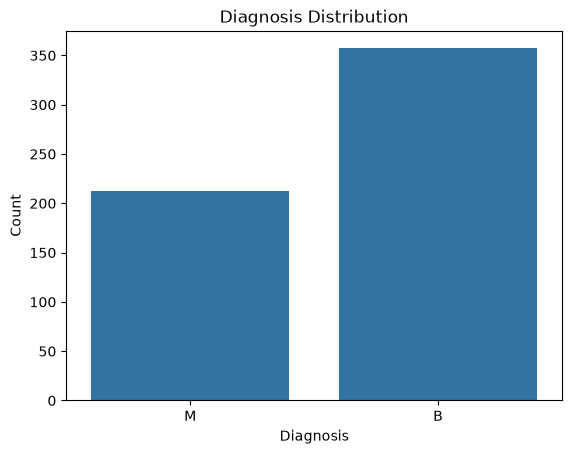

In [45]:
print("Target distribution before splitting:")
print(dataset["diagnosis"].value_counts())

sns.countplot(x=dataset["diagnosis"])
plt.title("Diagnosis Distribution")
plt.xlabel("Diagnosis")
plt.ylabel("Count")
plt.show()

In [46]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

Training features: (455, 30)
Testing features: (114, 30)


In [47]:
sc = StandardScaler()

X_train_scaled = sc.fit_transform(X_train)
X_test_scaled = sc.transform(X_test)

In [48]:
print("Before SMOTE:", Counter(y_train))

smote = SMOTE(random_state=42)
X_train_balanced, y_train_balanced = smote.fit_resample(
    X_train_scaled,
    y_train
)

print("After SMOTE:", Counter(y_train_balanced))

Before SMOTE: Counter({np.int64(0): 285, np.int64(1): 170})
After SMOTE: Counter({np.int64(1): 285, np.int64(0): 285})


In [49]:
rf_model = RandomForestClassifier(
    random_state=15,
    max_depth=15
)

rf_model.fit(X_train_balanced, y_train_balanced)
y_pred_rf = rf_model.predict(X_test_scaled)

In [50]:
dt_model = DecisionTreeClassifier(
    random_state=15,
    max_depth=15
)

dt_model.fit(X_train_balanced, y_train_balanced)
y_pred_dt = dt_model.predict(X_test_scaled)

In [52]:
svm_model = SVC(
    kernel="rbf",
    probability=True,
    random_state=42
)

svm_model.fit(X_train_balanced, y_train_balanced)
y_pred_svm = svm_model.predict(X_test_scaled)


C:\Users\Elsons elfakherx\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


In [53]:
lr_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

lr_model.fit(X_train_balanced, y_train_balanced)
y_pred_lr = lr_model.predict(X_test_scaled)


In [56]:
def evaluate_model(y_true, y_pred, y_probability, model_name):
    accuracy = accuracy_score(y_true, y_pred) * 100
    precision = precision_score(y_true, y_pred, zero_division=0) * 100
    recall = recall_score(y_true, y_pred, zero_division=0) * 100
    f1 = f1_score(y_true, y_pred, zero_division=0) * 100
    auc = roc_auc_score(y_true, y_probability) * 100

    print(f"{model_name} Results")
    print("-------------------------")
    print(f"Accuracy:  {accuracy:.2f}%")
    print(f"Precision: {precision:.2f}%")
    print(f"Recall:    {recall:.2f}%")
    print(f"F1 Score:  {f1:.2f}%")
    print(f"ROC-AUC:   {auc:.2f}%")

    return {
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1,
        "ROC-AUC": auc
    }


In [57]:
# Probability of class 1 (Malignant) for each model
rf_prob = rf_model.predict_proba(X_test_scaled)[:, 1]
dt_prob = dt_model.predict_proba(X_test_scaled)[:, 1]
svm_prob = svm_model.predict_proba(X_test_scaled)[:, 1]
lr_prob = lr_model.predict_proba(X_test_scaled)[:, 1]

rf_results = evaluate_model(y_test, y_pred_rf, rf_prob, "Random Forest")
dt_results = evaluate_model(y_test, y_pred_dt, dt_prob, "Decision Tree")
svm_results = evaluate_model(y_test, y_pred_svm, svm_prob, "SVM")
lr_results = evaluate_model(y_test, y_pred_lr, lr_prob, "Logistic Regression")


Random Forest Results
-------------------------
Accuracy:  96.49%
Precision: 97.50%
Recall:    92.86%
F1 Score:  95.12%
ROC-AUC:   99.74%
Decision Tree Results
-------------------------
Accuracy:  91.23%
Precision: 86.36%
Recall:    90.48%
F1 Score:  88.37%
ROC-AUC:   91.07%
SVM Results
-------------------------
Accuracy:  97.37%
Precision: 97.56%
Recall:    95.24%
F1 Score:  96.39%
ROC-AUC:   99.57%
Logistic Regression Results
-------------------------
Accuracy:  97.37%
Precision: 97.56%
Recall:    95.24%
F1 Score:  96.39%
ROC-AUC:   99.27%


In [58]:
results = pd.DataFrame(
    [rf_results, dt_results, svm_results, lr_results],
    index=["Random Forest", "Decision Tree", "SVM", "Logistic Regression"]
)

results.round(2)


,Accuracy,Precision,Recall,F1 Score,ROC-AUC
Random Forest,96.49,97.50,92.86,95.12,99.74
Decision Tree,91.23,86.36,90.48,88.37,91.07
SVM,97.37,97.56,95.24,96.39,99.57
Logistic Regression,97.37,97.56,95.24,96.39,99.27


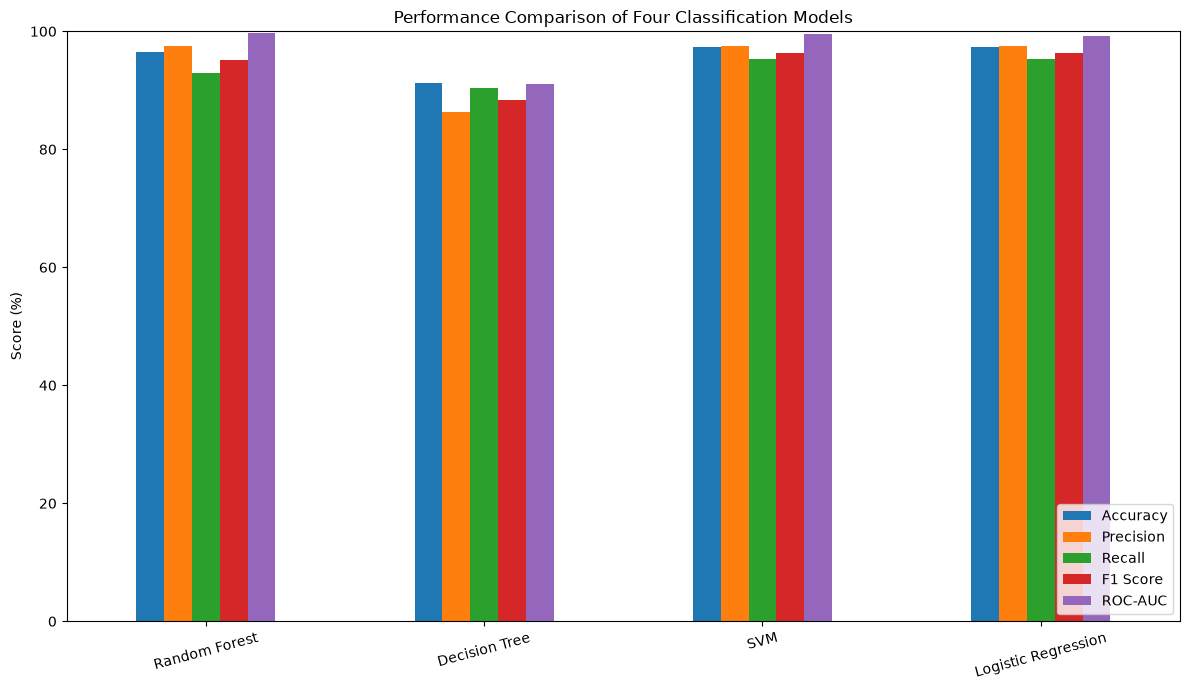

In [59]:
results.plot(kind="bar", figsize=(12, 7))
plt.title("Performance Comparison of Four Classification Models")
plt.ylabel("Score (%)")
plt.ylim(0, 100)
plt.xticks(rotation=15)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()


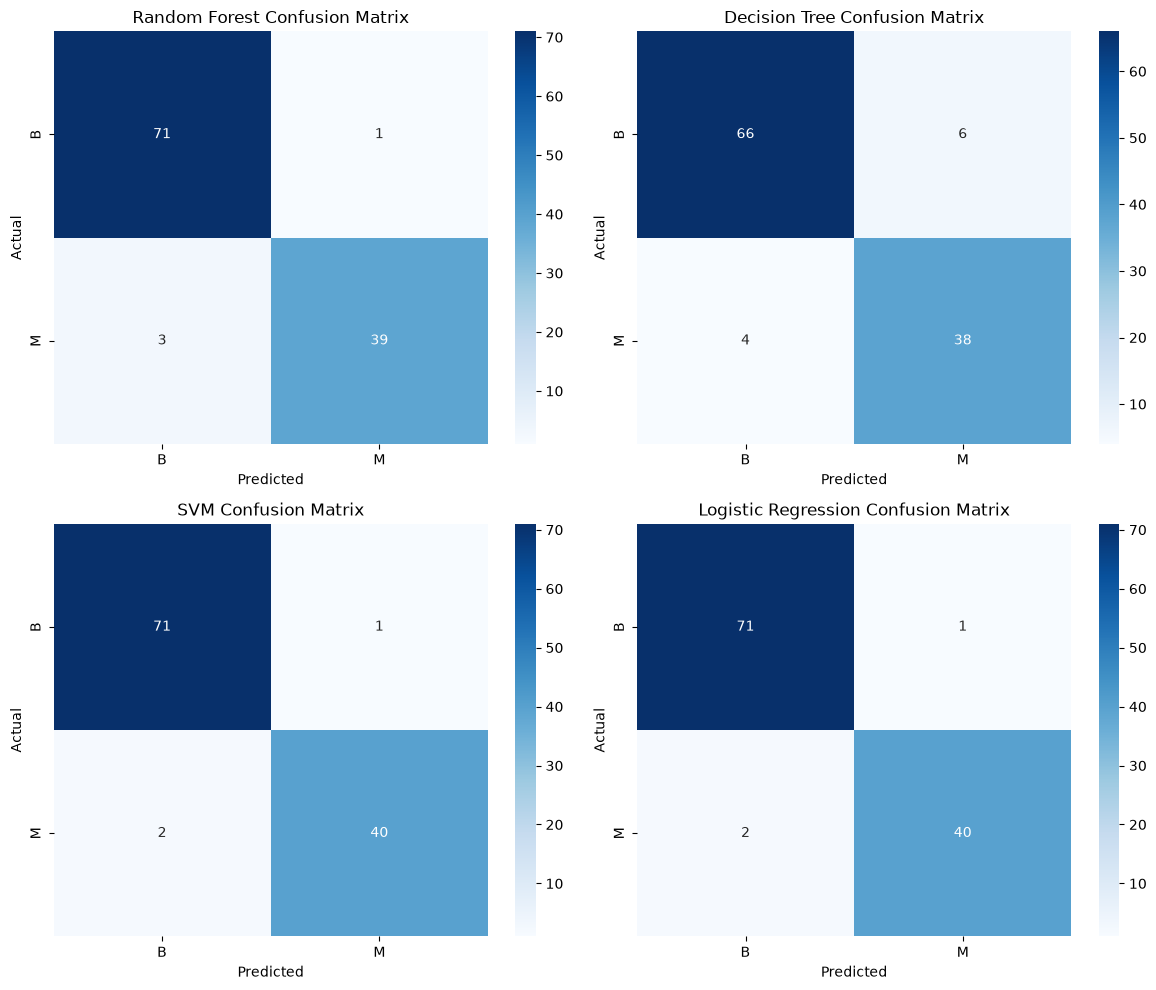

In [60]:
predictions = {
    "Random Forest": y_pred_rf,
    "Decision Tree": y_pred_dt,
    "SVM": y_pred_svm,
    "Logistic Regression": y_pred_lr
}

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.ravel()

for ax, (model_name, predictions_for_model) in zip(axes, predictions.items()):
    cm = confusion_matrix(y_test, predictions_for_model)
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=le.classes_,
        yticklabels=le.classes_,
        ax=ax
    )
    ax.set_title(f"{model_name} Confusion Matrix")
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.show()


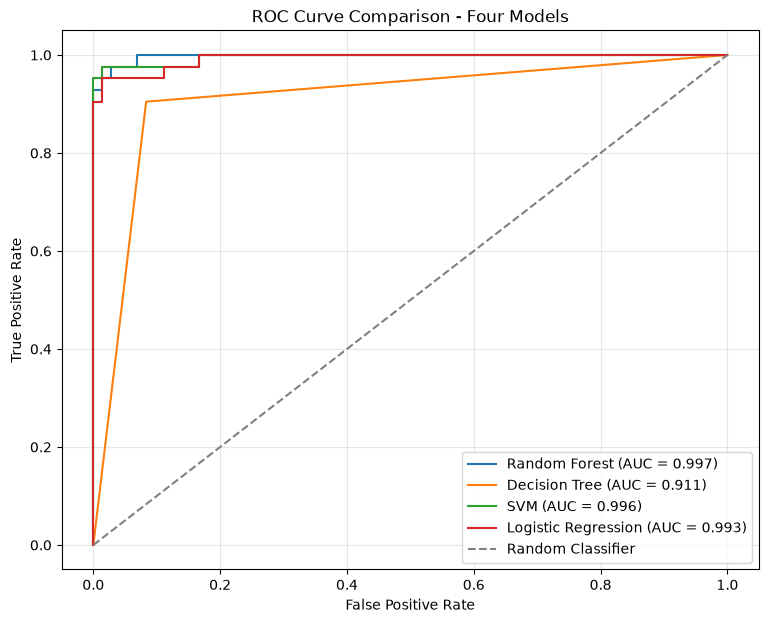

In [61]:
probabilities = {
    "Random Forest": rf_prob,
    "Decision Tree": dt_prob,
    "SVM": svm_prob,
    "Logistic Regression": lr_prob
}

plt.figure(figsize=(9, 7))

for model_name, probability in probabilities.items():
    fpr, tpr, _ = roc_curve(y_test, probability)
    auc_value = roc_auc_score(y_test, probability)
    plt.plot(fpr, tpr, label=f"{model_name} (AUC = {auc_value:.3f})")

plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random Classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison - Four Models")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


In [63]:
reports = {
    "Random Forest": y_pred_rf,
    "Decision Tree": y_pred_dt,
    "SVM": y_pred_svm,
    "Logistic Regression": y_pred_lr
}

for model_name, predictions_for_model in reports.items():
    print(f"{model_name} Classification Report")
    print(classification_report(
        y_test,
        predictions_for_model,
        target_names=le.classes_,
        zero_division=0
    ))


Random Forest Classification Report
              precision    recall  f1-score   support

           B       0.96      0.99      0.97        72
           M       0.97      0.93      0.95        42

    accuracy                           0.96       114
   macro avg       0.97      0.96      0.96       114
weighted avg       0.97      0.96      0.96       114

Decision Tree Classification Report
              precision    recall  f1-score   support

           B       0.94      0.92      0.93        72
           M       0.86      0.90      0.88        42

    accuracy                           0.91       114
   macro avg       0.90      0.91      0.91       114
weighted avg       0.91      0.91      0.91       114

SVM Classification Report
              precision    recall  f1-score   support

           B       0.97      0.99      0.98        72
           M       0.98      0.95      0.96        42

    accuracy                           0.97       114
   macro avg       0.97      0